# 07 · Voice evaluation: Sinhala speech in and speech out (Member 4: chatbot)

Everything here runs **locally**: no outside AI service. Models (all open, pretrained, used as they are):

| Role | Model | Licence |
|---|---|---|
| STT, CPU default (`STT_MODEL=small`) | `seniruk/whisper-small-si` (Whisper small fine-tuned for Sinhala) | Apache-2.0 |
| STT, compared | `SinhaSpeech/whisper-small-sinhala-run11` (Whisper small, OpenSLR-52 + collected data) | Apache-2.0 |
| STT, compared (`STT_MODEL=large`, GPU) | `kasunw/whisper-large-v3-sinhala` (Whisper large-v3, OpenSLR-52); less accurate and slower here, not recommended | Apache-2.0 |
| TTS Sinhala, primary (`TTS_VOICE=M2`) | `dialoglk/SinhalaVITS-TTS-M2` (Dialog Axiata + Dialog–UoM lab, Coqui VITS; 4 voices compared below) | MPL-2.0 |
| TTS Sinhala, fallback | `chan4lk/piper-tts-sinhala` (Piper VITS, trained on OpenSLR-30) | MIT |
| TTS English | `facebook/mms-tts-eng` | CC BY-NC 4.0 |

**Not done yet: our own STT fine-tuning.** It needs the team's recordings of `eval/voice/record_prompts.csv`
(notebook 06). Until then the "base vs fine-tuned" comparison cannot be made, and the farming-phrase test set is
**synthetic** (the prompts spoken by our TTS voices). Section 3 says so wherever it matters.

`RUN_EVAL = False` (as saved) shows the saved results in `eval/voice/results/`. `True` re-runs the CPU evaluations
(about 1.5 hours); the GPU numbers come from `python -m member4_chatbot.pipeline.voice_eval stt ... --device cuda`
run in an environment with a CUDA build of torch (see phase-6b.md).

In [1]:
RUN_EVAL = False
SETS_TO_RUN = [("small", "openslr30"), ("small-sinhaspeech", "openslr30"), ("small", "synthetic"),
               ("small-sinhaspeech", "synthetic")]

In [2]:
import sys, json
from pathlib import Path
HERE = Path.cwd(); ROOT = HERE.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from member4_chatbot.voice import evaluate as E, scoring
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 200)
if RUN_EVAL:
    for model, set_name in SETS_TO_RUN:
        E.run_stt(model, set_name, "cpu")
    E.run_tts_eval()
M = E.read_metrics()
R = E.RESULTS_DIR
print("result files:", sorted(p.name for p in R.glob("*.csv")))

result files: ['dictionary_candidates.csv', 'stt_large_openslr30_cuda.csv', 'stt_large_synthetic_cuda.csv', 'stt_small-sinhaspeech_openslr30_cpu.csv', 'stt_small-sinhaspeech_openslr30_cpu_n40.csv', 'stt_small-sinhaspeech_openslr30_cuda.csv', 'stt_small-sinhaspeech_synthetic_cuda.csv', 'stt_small_openslr30_cpu.csv', 'stt_small_openslr30_cpu_n40.csv', 'stt_small_openslr30_cuda.csv', 'stt_small_synthetic_cpu.csv', 'stt_small_synthetic_cuda.csv', 'tts_sentences.csv']


## 1. Test sets

In [3]:
sets = []
for name, path in E.SETS.items():
    if path.exists():
        d = pd.read_csv(path, keep_default_na=False)
        dur = d.duration_s.astype(float)
        sets.append({"set": name, "clips": len(d), "minutes": round(dur.sum() / 60, 1),
                     "speakers / voices": d.speaker.nunique() if "speaker" in d else d.voice.nunique() if "voice" in d else None,
                     "test-split clips": int((d.split == "test").sum()) if "split" in d else len(d)})
    else:
        sets.append({"set": name, "clips": 0, "minutes": 0, "speakers / voices": 0, "test-split clips": 0})
display(pd.DataFrame(sets).set_index("set"))
print("openslr30 = real read Sinhala (general, not farming); synthetic = our TTS reading the farming prompts;")
print("farm = the team's recordings of the prompts (empty until recorded).")

,clips,minutes,speakers / voices,test-split clips
set,,,,
openslr30,200,19.0,12,200
synthetic,498,35.2,5,148
farm,0,0.0,0,0


openslr30 = real read Sinhala (general, not farming); synthetic = our TTS reading the farming prompts;
farm = the team's recordings of the prompts (empty until recorded).


## 2. Speech-to-text: which pretrained model, and how fast

WER counts words, CER characters (spaces removed). Sinhala word boundaries vary in writing (හතළිස් පහ /
හතළිස්පහ, වී වලට / වීවලට), so **CER is the more reliable measure for Sinhala**; WER is reported too. Both texts are
normalised the same way first (digits as words, ZWJ removed, abbreviations joined: `member4_chatbot/voice/scoring.py`).

n     WER     CER  WER+dict  CER+dict  latency median ms   p95 ms  real-time factor
set       device  model                                                                                                   
openslr30 cpu     small              200  0.2449  0.0450    0.2449    0.0450             3909.2   4752.0             1.126
                  small-sinhaspeech  200  0.3230  0.0499    0.3230    0.0499             3751.8   4798.1             1.088
          cpu_n40 small               40  0.2432  0.0454    0.2432    0.0454             3721.1   4497.4             1.053
                  small-sinhaspeech   40  0.3446  0.0435    0.3446    0.0435             3906.2   4659.9             1.092
          cuda    large              200  0.3710  0.0772    0.3710    0.0772             5246.1   6838.7             1.398
                  small              200  0.2462  0.0453    0.2462    0.0453             1034.0   1475.1             0.299
                  small-sinhaspeech  200  0.3224  0.0498    0.3224    0.0498             1063.8   1431.8             0.310
synthetic cpu     small              148  0.6376  0.2519    0.6236    0.2465             4418.9   7528.5             1.593
          cuda    large              148  0.6442  0.2321    0.6358    0.2292             4821.9  10840.8             1.747
                  small              148  0.6348  0.2535    0.6217    0.2487             1694.8   4053.8             0.655
                  small-sinhaspeech  148  0.6301  0.2489    0.6161    0.2430             1674.9   3817.5             0.629

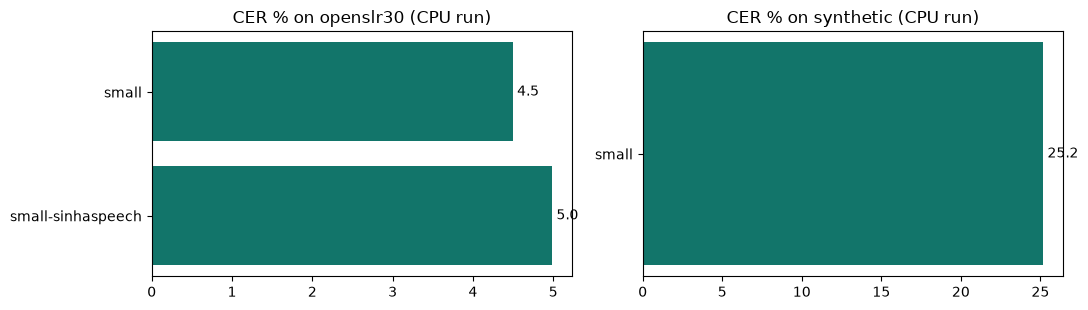

In [4]:
rows = []
for key, m in M.get("stt", {}).items():
    model, set_name, device = key.split("|")
    part = m["test_split"] or m["all"]
    rows.append({"model": model, "hf_id": m["model"], "set": set_name, "device": device, "n": part["n"],
                 "WER": part["wer"], "CER": part["cer"], "WER+dict": part["wer_dict"], "CER+dict": part["cer_dict"],
                 "latency median ms": m["latency_ms_median"], "p95 ms": m["latency_ms_p95"],
                 "real-time factor": m["real_time_factor"], "hardware": m["hardware"]})
stt = pd.DataFrame(rows).sort_values(["set", "device", "model"])
display(stt.drop(columns=["hf_id", "hardware"]).set_index(["set", "device", "model"]))
full = stt[~stt.device.str.contains("_n")]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for a, s in zip(ax, ["openslr30", "synthetic"]):
    d = full[(full.set == s) & (full.device == "cpu")]
    if len(d):
        a.barh(d.model, d.CER * 100, color="#12756A"); a.set_title(f"CER % on {s} (CPU run)"); a.invert_yaxis()
        for y, v in enumerate(d.CER * 100): a.text(v, y, f" {v:.1f}", va="center")
plt.tight_layout(); plt.show()

In [5]:
print("Hardware of each run:")
for h in stt.drop_duplicates("hardware").itertuples():
    print(f"  {h.device:>10}: {h.hardware}")
lat = stt[stt.set == "openslr30"][["model", "device", "n", "latency median ms", "p95 ms", "real-time factor"]]
print("\nSTT latency on OpenSLR-30 (per clip, after the model is loaded; median clip ≈ 3 s of speech):")
display(lat.set_index(["model", "device"]))

Hardware of each run:
         cpu: CPU Intel64 Family 6 Model 186 Stepping 2, GenuineIntel, 10 threads, torch 2.14.1+cpu
     cpu_n40: CPU 13th Gen Intel(R) Core(TM) i7-13620H, 10 threads, torch 2.14.1+cpu
        cuda: GPU NVIDIA GeForce RTX 4060 Laptop GPU (CPU 13th Gen Intel(R) Core(TM) i7-13620H), torch 2.14.1+cu130

STT latency on OpenSLR-30 (per clip, after the model is loaded; median clip ≈ 3 s of speech):


,,n,latency median ms,p95 ms,real-time factor
model,device,,,,
small,cpu,200,3909.2,4752.0,1.126
small-sinhaspeech,cpu,200,3751.8,4798.1,1.088
small,cpu_n40,40,3721.1,4497.4,1.053
small-sinhaspeech,cpu_n40,40,3906.2,4659.9,1.092
large,cuda,200,5246.1,6838.7,1.398
small,cuda,200,1034.0,1475.1,0.299
small-sinhaspeech,cuda,200,1063.8,1431.8,0.310


## 3. Farming phrases: base vs our fine-tuned model, and with vs without the term dictionary

**Our fine-tuned model: not trained yet** (no team recordings). The table below says so from
`artifacts/stt/finetuned/metrics.json` when it exists.

**The term dictionary** (`data/voice/stt_corrections.yaml`) was built only from mistakes on the **finetune-split**
phrases of the synthetic set; it is scored on the **test-split** phrases and on OpenSLR-30 (where it must not hurt).
The synthetic set is clean machine speech: it shows whether the models know farming words and numbers, not how
they cope with farmers' accents or field noise.

In [6]:
ft = ROOT / "artifacts" / "stt" / "finetuned" / "metrics.json"
if ft.exists():
    fm = json.loads(ft.read_text())
    display(pd.DataFrame(fm["test_phrases"]).T)
    print(fm["verdict"])
else:
    print("Base vs fine-tuned: NOT AVAILABLE. Our fine-tuning (notebook 06) waits for the team's recordings.")
dict_rows = []
for key, m in M.get("stt", {}).items():
    model, set_name, device = key.split("|")
    if "_n" in device:
        continue
    for split in ("test_split", "finetune_split"):
        p = m.get(split) or {}
        if p:
            dict_rows.append({"model": model, "set": set_name, "split": split.replace("_split", ""), "n": p["n"],
                              "CER": p["cer"], "CER + dict": p["cer_dict"], "WER": p["wer"], "WER + dict": p["wer_dict"],
                              "clips changed": p["clips_corrected"]})
display(pd.DataFrame(dict_rows).set_index(["model", "set", "split"]))
import yaml
entries = yaml.safe_load((ROOT / "data" / "voice" / "stt_corrections.yaml").read_text(encoding="utf-8"))["corrections"] or []
print(f"dictionary entries: {len(entries)}")
display(pd.DataFrame(entries))

Base vs fine-tuned: NOT AVAILABLE. Our fine-tuning (notebook 06) waits for the team's recordings.


n     CER  CER + dict     WER  WER + dict  clips changed
model             set       split                                                               
small-sinhaspeech openslr30 test      200  0.0499      0.0499  0.3230      0.3230              0
small             openslr30 test      200  0.0450      0.0450  0.2449      0.2449              0
                            test      200  0.0453      0.0453  0.2462      0.2462              0
small-sinhaspeech openslr30 test      200  0.0498      0.0498  0.3224      0.3224              0
                  synthetic test      148  0.2489      0.2430  0.6301      0.6161             13
                            finetune  350  0.2247      0.2194  0.5877      0.5733             31
small             synthetic test      148  0.2535      0.2487  0.6348      0.6217             13
                            finetune  350  0.2212      0.2140  0.6149      0.5968             41
                            test      148  0.2519      0.2465  0.6376      0.6236             13
                            finetune  350  0.2207      0.2135  0.6141      0.5960             41
large             openslr30 test      200  0.0772      0.0772  0.3710      0.3710              0
                  synthetic test      148  0.2321      0.2292  0.6442      0.6358              9
                            finetune  350  0.2408      0.2355  0.6722      0.6586             33

dictionary entries: 18


,heard,write,evidence
0,යුරියා,යූරියා,"18x; synthetic set, finetune split, whisper-small Sinhala models (seniruk + SinhaSpeec..."
1,උරියා,යූරියා,"3x; synthetic set, finetune split, whisper-small Sinhala models (seniruk + SinhaSpeech..."
2,යෝරියා,යූරියා,"3x; synthetic set, finetune split, whisper-small Sinhala models (seniruk + SinhaSpeech..."
3,ලූරියා,යූරියා,"2x; synthetic set, finetune split, whisper-small Sinhala models (seniruk + SinhaSpeech..."
4,දුම්බුරු,දුඹුරු,"5x; synthetic set, finetune split, whisper-small Sinhala models (seniruk + SinhaSpeech..."
5,කුම්බුරේ,කුඹුරේ,"5x; synthetic set, finetune split, whisper-small Sinhala models (seniruk + SinhaSpeech..."
6,කුම්බුරුවේ,කුඹුරේ,"2x; synthetic set, finetune split, whisper-small Sinhala models (seniruk + SinhaSpeech..."
7,ආකරයකට,අක්කරයකට,"4x; synthetic set, finetune split, whisper-small Sinhala models (seniruk + SinhaSpeech..."
8,අකරයකට,අක්කරයකට,"2x; synthetic set, finetune split, whisper-small Sinhala models (seniruk + SinhaSpeech..."
9,එක්ටියාරයකට,හෙක්ටයාරයකට,"2x; synthetic set, finetune split, whisper-small Sinhala models (seniruk + SinhaSpeech..."


In [7]:
# farming words the default model gets wrong on the synthetic TEST split (after the dictionary)
f = R / "stt_small_synthetic_cpu.csv"
if f.exists():
    d = pd.read_csv(f, keep_default_na=False)
    d = d[d.split == "test"].copy()
    d["cer"] = [scoring.cer([r], [h]) for r, h in zip(d.ref, d.hyp_dict)]
    print(f"test-split clips: {len(d)}; clips with CER = 0: {(d.cer == 0).mean():.0%}")
    display(d.sort_values("cer", ascending=False).head(12)[["id", "ref", "hyp_dict", "cer"]])

test-split clips: 148; clips with CER = 0: 3%


,id,ref,hyp_dict,cer
399,P200_M1,ලබන මාසේ මගේ පසේ නයිට්‍රජන් අඩු වෙයිද?,මෙම්මේ දීමට යොදුවීමට යොදුවීමට යොදීමට යොදීමට යොදීමට යොදීමට යොදීමට යොදීමට යොදීමට යොදීමට ...,3.466667
22,P012_M1,පළමු හීය සීසෑම කොච්චර කලින් කරන්න ඕනද?,ගලමු කිය සී සෑම කොස්චර කලින් ක්‍රින් ක්රින් ක්රින් ක්රින් ක්රින් ක්රින් ක්රින් ක්රින් ...,2.709677
435,P218_piper,"මාස 3 වී සඳහා යූරියා යොදන කාලසටහන කුමක්ද? (තෙත් කලාපයේ, වාරි ජලයෙන් වගා කරන)",මාස තුන මේ සන්දහයෝ රියා යොදැන කාලසට අන්න කුමක් ද ප්ත්ත්ත්ත්ත්ත්ත්ත්ත්ත්ත්ත්ත්ත්ත්ත්ත්ත...,1.262295
148,P075_piper,වපුරනවද සිටුවනවද කොයිකද හොඳ?,උපරණාන්ද සිටුවන නොන්ද කොයිකද හොන්දත්,0.583333
347,P174_F1,වතුර ඉතිරි කරන ක්‍රම මොනවද?,මාතුනේ ඉතිරි කරන්න ක්‍රමුණු වුණාද?,0.571429
101,P051_F2,මගේ කුඹුරේ පී.එච්. අගය කීයද?,මගේ කුඹුරේ තිති ඒෂ් රොලිය කියද?,0.523810
50,P026_F1,ලබන මැතිවරණයෙන් බලයට එන්නේ කවුද?,ලබන්ම මැතිවරණයින් බලෙත ඉඳික් කබේ.,0.481481
480,P241_F1,At 303 කොළ පාළුවට ඔරොත්තු දෙනවද?,කෙතියි තුන්ස් තිය තුන කොල්ල පළලුවත් ඔරොත්තු දෙනාද?,0.470588
100,P051_F1,මගේ කුඹුරේ පී.එච්. අගය කීයද?,මගේ කුඹ්බුදී තීති.අගය කීද?,0.428571
88,P045_piper,පොස්පරස් අඩු වුණාම මොකද වෙන්නේ?,ඔස්කර සටු උනාව මොකද වෙන්නේද,0.423077


### Which TTS voice is easiest to understand?
The synthetic set uses 5 voices (each prompt by 2 of them), so the STT error per voice is also an automatic
intelligibility score for our TTS voices. The default Sinhala voice (`TTS_VOICE`) was chosen from this table.

In [8]:
rows = []
for f in sorted(R.glob("stt_*_synthetic_*.csv")):
    if "_n" in f.stem.split("_")[-1]:
        continue
    d = pd.read_csv(f, keep_default_na=False)
    d["voice"] = d.id.str.split("_").str[1]
    for v, g in d.groupby("voice"):
        rows.append({"stt run": f.stem.removeprefix("stt_"), "voice": v, "CER": scoring.cer(list(g.ref), list(g.hyp_raw))})
pv = pd.DataFrame(rows).pivot(index="voice", columns="stt run", values="CER")
pv["mean"] = pv.mean(axis=1)
display(pv.sort_values("mean").round(3))

stt run,large_synthetic_cuda,small-sinhaspeech_synthetic_cuda,small_synthetic_cpu,small_synthetic_cuda,mean
voice,,,,,
M2,0.196,0.186,0.170,0.172,0.181
F2,0.205,0.222,0.177,0.178,0.196
piper,0.231,0.265,0.234,0.236,0.241
M1,0.277,0.195,0.278,0.277,0.257
F1,0.281,0.297,0.290,0.290,0.289


## 4. Text-to-speech: failures, latency, intelligibility

Texts: every answer of the 60-question evaluation run (`eval/results/results.csv`) plus the fixed bilingual texts,
normalised (`tts_text.py`) and spoken sentence by sentence. A **failure** is a sentence where the voice was given
something it cannot read (Latin letters or digits left in a Sinhala sentence, characters outside the voice's
alphabet, or empty audio). **Round-trip CER** is our STT run on the synthesised audio against the text the voice
was given: an automatic intelligibility check, not a substitute for a listener.

,sentences,failed_sentences,failure_rate,latency_ms_per_sentence_median,latency_ms_per_sentence_p95,real_time_factor,roundtrip_cer
mms,175.0,0.0,0.0000,1670.6,4580.5,0.344,NaN
piper,156.0,5.0,0.0321,248.6,745.0,0.054,0.2827
sinhalavits,156.0,5.0,0.0321,3102.7,8202.0,0.476,0.2463


{'voice': 'M2', 'hardware': 'CPU 13th Gen Intel(R) Core(TM) i7-13620H, 10 threads, torch 2.14.1+cpu', 'texts': 66, 'roundtrip_stt': 'small', 'note': 'roundtrip_cer = CER of our STT on the TTS audio vs the text the voice was given; an automatic intelligibility proxy, not a listening score'}
failed sentences: 10 of 487


,engine,text_id,source,spoken,leftovers
83,sinhalavits,Q21,"2 Weeks, 50.","දෙක Weeks, පනහ.",Weeks
84,sinhalavits,Q21,"4 Weeks, 75, 25.","හතර Weeks, හැත්තෑපහ, විසිපහ.",Weeks
85,sinhalavits,Q21,"7 Weeks, 35.","හත Weeks, තිස්පහ.",Weeks
326,sinhalavits,REFUSE_OUT_OF_SCOPE_si,ඔබේ ප්‍රශ්නය කෘෂිකර්ම නිලධාරියෙකුට යොමු කළා (යොමු අංකය ESC-3F9A1C).,ඔබේ ප්‍රශ්නය කෘෂිකර්ම නිලධාරියෙකුට යොමු කළා (යොමු අංකය ඊ එස් සී-තුනFනවයAඑකසෙල්සියස් අං...,F; A
330,sinhalavits,REFUSE_NOT_FOUND_si,ඔබේ ප්‍රශ්නය කෘෂිකර්ම නිලධාරියෙකුට යොමු කළා (යොමු අංකය ESC-3F9A1C).,ඔබේ ප්‍රශ්නය කෘෂිකර්ම නිලධාරියෙකුට යොමු කළා (යොමු අංකය ඊ එස් සී-තුනFනවයAඑකසෙල්සියස් අං...,F; A
332,piper,Q21,"2 Weeks, 50.","දෙක Weeks, පනහ.",Weeks
333,piper,Q21,"4 Weeks, 75, 25.","හතර Weeks, හැත්තෑපහ, විසිපහ.",Weeks
334,piper,Q21,"7 Weeks, 35.","හත Weeks, තිස්පහ.",Weeks
484,piper,REFUSE_OUT_OF_SCOPE_si,ඔබේ ප්‍රශ්නය කෘෂිකර්ම නිලධාරියෙකුට යොමු කළා (යොමු අංකය ESC-3F9A1C).,ඔබේ ප්‍රශ්නය කෘෂිකර්ම නිලධාරියෙකුට යොමු කළා (යොමු අංකය ඊ එස් සී-තුනFනවයAඑකසෙල්සියස් අං...,F; A
486,piper,REFUSE_NOT_FOUND_si,ඔබේ ප්‍රශ්නය කෘෂිකර්ම නිලධාරියෙකුට යොමු කළා (යොමු අංකය ESC-3F9A1C).,ඔබේ ප්‍රශ්නය කෘෂිකර්ම නිලධාරියෙකුට යොමු කළා (යොමු අංකය ඊ එස් සී-තුනFනවයAඑකසෙල්සියස් අං...,F; A


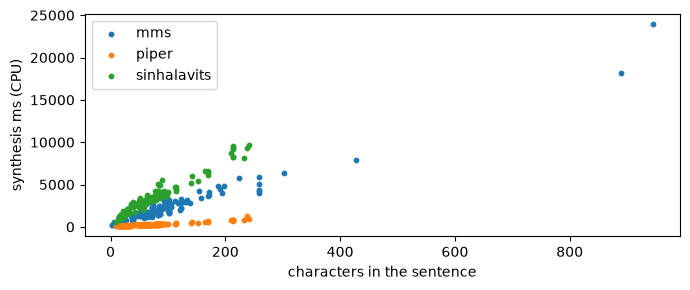

In [9]:
tts = M.get("tts", {}).get("cpu", {})
info = tts.pop("_info", {}) if tts else {}
display(pd.DataFrame(tts).T)
print(info)
s = pd.read_csv(R / "tts_sentences.csv", keep_default_na=False) if (R / "tts_sentences.csv").exists() else pd.DataFrame()
if len(s):
    bad = s[s.failed.astype(str) == "True"]
    print(f"failed sentences: {len(bad)} of {len(s)}")
    display(bad[["engine", "text_id", "source", "spoken", "leftovers"]].head(15))
    fig, ax = plt.subplots(figsize=(7, 3))
    for eng, d in s.groupby("engine"):
        ax.scatter(d.chars, d.synth_ms, s=10, label=eng)
    ax.set_xlabel("characters in the sentence"); ax.set_ylabel("synthesis ms (CPU)"); ax.legend(); plt.tight_layout(); plt.show()

In [10]:
if len(s) and "roundtrip_cer" in s:
    si = s[(s.lang == "si") & (s.roundtrip_cer != "")].copy()
    si["roundtrip_cer"] = si.roundtrip_cer.astype(float)
    print("round-trip CER per engine (Sinhala sentences):")
    display(si.groupby("engine").roundtrip_cer.describe()[["count", "mean", "50%", "max"]])
    print("worst round trips (SinhalaVITS):")
    display(si[si.engine == "sinhalavits"].sort_values("roundtrip_cer", ascending=False).head(6)[["spoken", "roundtrip_hyp", "roundtrip_cer"]])

round-trip CER per engine (Sinhala sentences):


,count,mean,50%,max
engine,,,,
piper,156.0,0.270790,0.25000,1.0
sinhalavits,156.0,0.228599,0.21895,1.0


worst round trips (SinhalaVITS):


,spoken,roundtrip_hyp,roundtrip_cer
319,ආයුබෝවන්!,පාලි බොහොයන්,1.0000
84,"හතර Weeks, හැත්තෑපහ, විසිපහ.",හතර වෙක්ස් ඇතැප හා විසේපා,0.5909
83,"දෙක Weeks, පනහ.",දෙක වේස් පනා,0.5455
151,බීජ පේළි වශයෙන් වැපිරීමෙන් යාන්ත්‍රික වල් පැලෑටි වල පාලනය බෝගය පහසුවෙන් කළමනාකරණය කිරී...,බීජ පේළිවොස්යෙන් වැපිරීමෙන් යාන්ත්‍රික්කවල් පැරෑටි වල පාලනය බෝගියේ පහසුවෙන් කළමනාකරණය ...,0.5260
131,අවශ්‍යතාවය හෙක්ටයාරයකට කිලෝ එකසිය විසිපහක් පමණ බීජ සකස් කිරීම පැය හතළිස්අටක් පිරිසිදු ...,අවශ්යතාවය හෙක්තිාරයකට කියලු එක සිය විසි පහත් පමණ බීජ සකස් කිරීම පැය හතළිසටක් පෙරිසදු ද...,0.5100
140,වී වගාවට අහිතකර බලපෑමක් ඇතිකරන වල් පැළෑටි මර්දනය කල යුතුය.වගාව කෙරෙහි වල් පැලෑටි වල හා...,වී වදාවට අහිතකර බලපෑමක් ඇතිකරන වල් පැයාටි මර්දනය කරයුතුය. වදාව කෙරෙහි වල් පැලෑටි වල හා...,0.5099


## 5. Listening score (1–5) from a Sinhala speaker

In [11]:
sheet = ROOT / "eval" / "voice" / "listening" / "listening_scores.xlsx"
if sheet.exists():
    ls = pd.read_excel(sheet, sheet_name="scores")
    scored = ls.dropna(subset=["naturalness_1_5"])
    if len(scored):
        display(scored.groupby("engine").agg(items=("item", "count"), mean_score=("naturalness_1_5", "mean"),
                numbers_ok=("numbers_correct_yes_no", lambda x: (x == "yes").mean())))
    else:
        print(f"PENDING: {len(ls)} audio files are ready in eval/voice/listening/, but no scores are filled in yet.")
else:
    print("PENDING: run python -m member4_chatbot.pipeline.voice_eval listening")

PENDING: run python -m member4_chatbot.pipeline.voice_eval listening


## 6. Summary

In [12]:
def get(model, set_name, device="cpu", split="test_split", k="cer"):
    m = M.get("stt", {}).get(f"{model}|{set_name}|{device}")
    return (m.get(split) or m["all"]).get(k) if m else None
summary = {
    "STT default (small) CER, OpenSLR-30": get("small", "openslr30"),
    "STT default CER, synthetic farming test phrases (raw / +dictionary)":
        (get("small", "synthetic"), get("small", "synthetic", k="cer_dict")),
    "our fine-tuned STT": "not trained yet (waits for team recordings)" if not ft.exists() else json.loads(ft.read_text())["verdict"],
    "TTS failure rate (SinhalaVITS / Piper)": (tts.get("sinhalavits", {}).get("failure_rate"), tts.get("piper", {}).get("failure_rate")),
    "TTS round-trip CER (SinhalaVITS / Piper)": (tts.get("sinhalavits", {}).get("roundtrip_cer"), tts.get("piper", {}).get("roundtrip_cer")),
    "listening score": "pending" if not sheet.exists() or pd.read_excel(sheet).naturalness_1_5.isna().all() else "see section 5",
}
for k, v in summary.items():
    print(f"{k}: {v}")

STT default (small) CER, OpenSLR-30: 0.045
STT default CER, synthetic farming test phrases (raw / +dictionary): (0.2519, 0.2465)
our fine-tuned STT: not trained yet (waits for team recordings)
TTS failure rate (SinhalaVITS / Piper): (0.0321, 0.0321)
TTS round-trip CER (SinhalaVITS / Piper): (0.2463, 0.2827)
listening score: pending
